# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

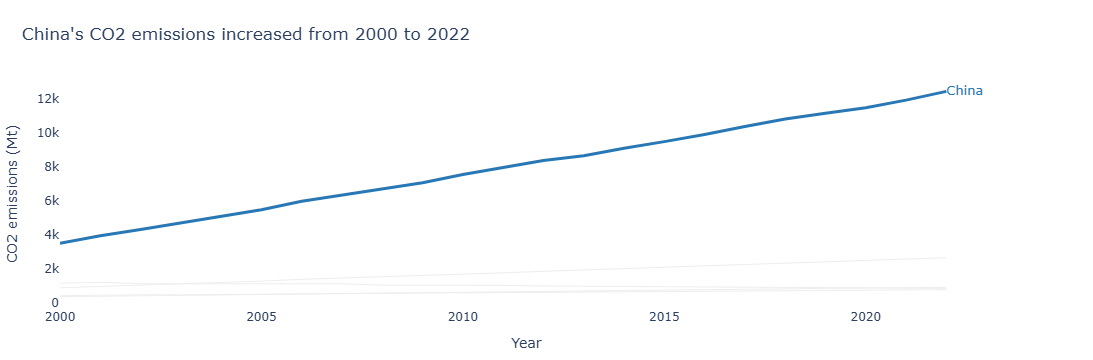

China's first recorded emissions: 3513.80 Mt
China's latest recorded emissions: 12409.50 Mt
Absolute change: 8895.70 Mt


In [3]:
# Task — Multi-series line with highlight
# YOUR CODE HERE

# Task — Multi-series line with highlight

# 1. Select Asian countries
asia_df = df[
    df["Region"].astype(str).str.contains("Asia", case=False, na=False)
].copy()

# 2. Choose China as the highlighted country
highlight_country = "China"

if asia_df.empty:
    raise ValueError("No Asian countries found. Check the Region column.")

if highlight_country not in asia_df["Country"].unique():
    raise ValueError("China was not found in the Asian countries dataset.")

# 3. Create the line chart
fig = go.Figure()

# Plot every Asian country in light grey
for country in asia_df["Country"].unique():
    country_data = (
        asia_df[asia_df["Country"] == country]
        .sort_values("Year")
    )

    if country != highlight_country:
        fig.add_trace(
            go.Scatter(
                x=country_data["Year"],
                y=country_data["CO2_Mt"],
                mode="lines",
                line=dict(color="#EEEEEE", width=1),
                hovertemplate=(
                    country
                    + "<br>Year: %{x}"
                    + "<br>CO2: %{y:.2f} Mt"
                    + "<extra></extra>"
                ),
                showlegend=False
            )
        )

# 4. Highlight China in blue
china_data = (
    asia_df[asia_df["Country"] == highlight_country]
    .sort_values("Year")
    .dropna(subset=["CO2_Mt"])
)

fig.add_trace(
    go.Scatter(
        x=china_data["Year"],
        y=china_data["CO2_Mt"],
        mode="lines",
        line=dict(color="#2878B5", width=3),
        name=highlight_country,
        hovertemplate=(
            "China"
            + "<br>Year: %{x}"
            + "<br>CO2: %{y:.2f} Mt"
            + "<extra></extra>"
        ),
        showlegend=False
    )
)

# 5. Label China directly at the end of its line
last_year = china_data["Year"].iloc[-1]
last_emissions = china_data["CO2_Mt"].iloc[-1]

fig.add_trace(
    go.Scatter(
        x=[last_year],
        y=[last_emissions],
        mode="text",
        text=["China"],
        textposition="middle right",
        textfont=dict(color="#2878B5", size=13),
        showlegend=False,
        hoverinfo="skip"
    )
)

# 6. Calculate China's actual change in emissions
first_emissions = china_data["CO2_Mt"].iloc[0]
change = last_emissions - first_emissions

if change > 0:
    story = "increased"
elif change < 0:
    story = "decreased"
else:
    story = "remained stable"

# 7. Add an insight title and clean styling
fig.update_layout(
    title=dict(
        text=(
            f"China's CO2 emissions {story} "
            f"from {china_data['Year'].iloc[0]} "
            f"to {last_year}"
        ),
        x=0.02,
        xanchor="left"
    ),
    xaxis_title="Year",
    yaxis_title="CO2 emissions (Mt)",
    template="plotly_white",
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=False,
    margin=dict(l=60, r=100, t=80, b=50)
)

fig.update_xaxes(showgrid=False, showline=False, zeroline=False)
fig.update_yaxes(showgrid=False, showline=False, zeroline=False)

fig.show()

print(f"China's first recorded emissions: {first_emissions:.2f} Mt")
print(f"China's latest recorded emissions: {last_emissions:.2f} Mt")
print(f"Absolute change: {change:.2f} Mt")

